# 2. Cleaning (WELFake)

How the cleaning rules were found, what was decided, and what the cleaning did. The description of the raw data
is in `01-data-analysis.ipynb`; the cleaning code is in `fake_news.data.clean` and every rule, with its group,
source and a real example, in `fake_news.data.markers`. The full decision record is
`reports/cleaning/DECISIONS.md`.

**Principle:** *remove what identifies the outlet or the scraping process; keep what the author wrote.*

Only counting and plotting; no model is trained. The leak scan (training split only) runs here: in section 3
on the round-1 data, in section 7 on the final data.

| Section | Content |
|---|---|
| 1 | Starting point |
| 2 | Round 1: where boilerplate lives |
| 3 | Round 2: systematic leak scan and the decisions |
| 4 | The rules and what they matched; before/after examples |
| 5 | Dropped rows: empty, non-English, duplicates |
| 6 | What we keep on purpose (G4–G8) |
| 7 | Result and the final dataset |

**Before running:** `pip install -e .` (see the README); data is prepared automatically. Runtime about
4 minutes (mostly the two leak scans), about 2.5 GB of memory. Figures are saved to `reports/figures/`.

In [1]:
%load_ext autoreload
%autoreload 2

import json
import re
import tempfile
import textwrap
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from sklearn.feature_extraction.text import CountVectorizer

from fake_news import config
from fake_news.data import load_clean, load_dataset, load_raw, load_splits
from fake_news.data.clean import build_rule_subset, normalize
from fake_news.data.load import read_clean_csv
from fake_news.data.markers import KEPT_SIGNALS, ROW_FILTERS
from fake_news.data.split import make_random_split

pd.set_option("display.max_colwidth", 130)
pd.set_option("display.width", 220)
LOG = config.CLEANING_REPORT_DIR

# ---- notebook helpers (counting and plotting only) ----
REAL, FAKE = "#2a78d6", "#eb6834"  # real = blue, fake = orange in every figure
INK2, MUTED, GRID, AXIS, SURFACE = "#52514e", "#898781", "#e1e0d9", "#c3c2b7", "#fcfcfb"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE, "axes.edgecolor": AXIS,
    "axes.labelcolor": INK2, "xtick.color": MUTED, "ytick.color": INK2, "axes.spines.top": False,
    "axes.spines.right": False, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "font.size": 10, "axes.titlesize": 11, "axes.titlelocation": "left", "legend.frameon": False, "figure.dpi": 110,
})


def per_class(mask, labels):
    "Articles where `mask` is True, per class, and the share that is fake."
    v = labels[mask].value_counts().reindex([0, 1], fill_value=0)
    return pd.Series({"real": int(v[0]), "fake": int(v[1]), "share_fake": round(v[1] / max(1, v.sum()), 3)})


def class_table(rows):
    return pd.DataFrame(rows).T.astype({"real": int, "fake": int})


def class_bars(ax, names, real, fake, title, xlabel="articles", values=False):
    "Grouped horizontal bars, real vs fake."
    y, h = np.arange(len(names)), 0.38
    bars = [ax.barh(y - h / 2 - 0.02, real, height=h, color=REAL, label="real"),
            ax.barh(y + h / 2 + 0.02, fake, height=h, color=FAKE, label="fake")]
    if values:
        for b in bars:
            ax.bar_label(b, labels=[f"{v:,.0f}" for v in b.datavalues], padding=4, color=INK2, fontsize=9)
        ax.margins(x=0.12)
    ax.set_yticks(y, list(names))
    ax.invert_yaxis()
    ax.grid(axis="y", visible=False)
    ax.set(title=title, xlabel=xlabel)
    ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1.0))


def save(fig, name):
    fig.tight_layout()
    fig.savefig(config.FIGURES_DIR / f"{name}.png", dpi=150)


def top_by_class(values, labels, k=10):
    "The k most common values per class, side by side."
    cols = {}
    for name, y in (("real", 0), ("fake", 1)):
        vc = values[(labels == y) & values.notna() & values.ne("")].value_counts().head(k)
        cols[(name, "text")], cols[(name, "articles")] = list(vc.index), list(vc.values)
    return pd.DataFrame(cols)

## 1. Starting point

From notebook 01: 72,134 articles (label 1 = fake). Outlet signatures are almost perfectly one class (60% of the
real articles are Reuters wire stories), 782 of the 783 empty texts are fake, ~8,500 rows are exact duplicates and a few
hundred articles are not in English.

In [2]:
raw = load_raw()
labels = raw["label"]
title, text = raw["title"].fillna(""), raw["text"].fillna("")
print(f"{len(raw):,} raw articles, {labels.mean():.1%} fake")

72,134 raw articles, 51.4% fake


## 2. Round 1: where boilerplate lives

Boilerplate sits at the start and end of articles and in titles. The most common openings and endings per class
show it immediately:

In [3]:
display(Markdown("**Most common first four words**"))
display(top_by_class(text.str.extract(r"^\s*(\S+(?:\s+\S+){0,3})")[0], labels))
display(Markdown("**Most common last five words**"))
display(top_by_class(text.str[-300:].str.extract(r"(\S+(?:\s+\S+){0,4})\s*$")[0], labels))

**Most common first four words**

real                                 fake         
                                text articles                        text articles
0        WASHINGTON (Reuters) - U.S.     1658      21st Century Wire says      693
1         WASHINGTON (Reuters) - The     1549              Tune in to the      203
2               NEW YORK (Reuters) -      726             Get short URL 0       65
3   WASHINGTON (Reuters) - President      667              It s no secret       61
4           WASHINGTON (Reuters) - A      412    This post was originally       53
5  WASHINGTON (Reuters) - Republican      268     Share on Facebook Share       53
6            MEXICO CITY (Reuters) -      227  Next Prev Swipe left/right       49
7          BEIJING (Reuters) - China      193       Donald Trump has been       49
8         UNITED NATIONS (Reuters) -      185          You are here: Home       48
9         LONDON (Reuters) - British      166              If there s one       47

**Most common last five words**

real                                              fake         
                                         text articles                                     text articles
0               Pam Key on Twitter @pamkeyNEN      225           image via video screen capture      513
1              in its creation or production.      180             & BECOME A MEMBER @21WIRE.TV      271
2           us know at briefing@nytimes. com.      157           & BECOMING A MEMBER @21WIRE.TV      252
3           Press contributed to this report.      135  image via Chip Somodevilla/Getty Images      188
4        Ian Hanchett on Twitter @IanHanchett      116         image via Alex Wong/Getty Images      164
5       the author at igcolonel@hotmail. com.      114              BECOME A MEMBER @ 21WIRE.TV      147
6     Daniel Nussbaum on Twitter: @dznussbaum      107      image via Drew Angerer/Getty Images      144
7             Jeff Poor on Twitter @jeff_poor      105       image via Win McNamee/Getty Images      125
8        Trent Baker on Twitter @MagnifiTrent      102                       on We Are Change .      112
9  him directly at awrhawkins@breitbart. com.      100       image via Mark Wilson/Getty Images      103

- Real articles open with a Reuters dateline ("WASHINGTON (Reuters) - …") and end with author bylines
  ("Follow Pam Key on Twitter …"), agency credits and newsletter text.
- Fake articles end with image credits ("… image via Chip Somodevilla/Getty Images") and 21st Century Wire
  boilerplate.

Titles carry the outlet's name as a suffix:

In [4]:
suffix = title.map(normalize).str.extract(r"\s[-|·]\s([^-|·]{2,60})$")[0]
suf = pd.DataFrame({"suffix": suffix, "label": labels}).dropna().groupby("suffix")["label"].agg(titles="size", share_fake="mean")
suf[suf.titles >= 8].sort_values("titles", ascending=False).round(3)

,titles,share_fake
suffix,,
The New York Times,6223,0.000
Breitbart,2340,0.001
America's Finest News Source,109,1.000
TruthFeed,106,1.000
Russia News Now,61,1.000
New Eastern Outlook,43,1.000
sources,39,0.000
Новое восточное обозрение,38,1.000
EndingFed News Network,37,1.000


These findings became the 15 round-1 rules (group **R1**): Reuters datelines, outlet title suffixes, title tags
such as "(VIDEO)", image and Getty credits, URLs, emails, @handles, 21WIRE boilerplate, social bylines and agency
credits.

## 3. Round 2: systematic leak scan (training split)

Manual inspection only finds what you think of looking for. The leak scan counts, on the **training split
only**, every 1–2 word phrase that occurs in ≥ 50 articles and is ≥ 98% one class, with where it usually sits
(`pos`: 0 = start of the article, 1 = end) and an example. Validation and test articles are never looked at.
Counting only: no model is trained.

In [5]:
MIN_ARTICLES, MIN_SHARE = 50, 0.98


def position_and_example(docs, phrase, rows):
    "Median relative position of the phrase in up to 40 articles (0 = start, 1 = end) and one example snippet."
    pat = re.compile(r"\b" + r"\W+".join(map(re.escape, phrase.split())) + r"\b")
    positions, example = [], ""
    for i in rows[:40]:
        s = docs[i]
        m = pat.search(s)
        if not m:
            continue
        positions.append(m.start() / max(1, len(s)))
        if not example:
            a, b = max(0, m.start() - 70), min(len(s), m.end() + 70)
            example = ("…" if a else "") + s[a:b] + ("…" if b < len(s) else "")
    return (round(float(np.median(positions)), 2) if positions else float("nan")), example


def leak_scan(train):
    "Every phrase in >= MIN_ARTICLES training articles that is >= MIN_SHARE one class (about 2 minutes)."
    docs, y = train["content"].tolist(), train["is_fake"].to_numpy()
    cv = CountVectorizer(ngram_range=(1, 2), min_df=MIN_ARTICLES, binary=True, dtype=np.int32)
    X = cv.fit_transform(docs)
    vocab = cv.get_feature_names_out()
    n_fake, n_real = np.asarray(X[y == 1].sum(0)).ravel(), np.asarray(X[y == 0].sum(0)).ravel()
    share_fake = n_fake / (n_fake + n_real)
    rows = []
    for j in np.where((share_fake >= MIN_SHARE) | (share_fake <= 1 - MIN_SHARE))[0]:
        pos, ex = position_and_example(docs, vocab[j], X[:, j].nonzero()[0])
        rows.append({"phrase": vocab[j], "docs": int(n_fake[j] + n_real[j]), "real": int(n_real[j]),
                     "fake": int(n_fake[j]), "side": "FAKE" if share_fake[j] >= MIN_SHARE else "REAL",
                     "pos": pos, "example": ex})
    phrases = pd.DataFrame(rows).sort_values("docs", ascending=False, ignore_index=True)
    display(Markdown(
        f"{len(train):,} training articles: **{len(phrases)}** of {len(vocab):,} frequent phrases are ≥ 98% one class "
        f"({(phrases.side == 'FAKE').sum()} fake-only, {(phrases.side == 'REAL').sum()} real-only)."))
    return phrases

In [6]:
# Round-1 data: the raw data cleaned with the 15 R1 rules only (no language filter), rebuilt in a temporary
# folder that is deleted afterwards (~3 min), split 70/15/15 with the same function and seed as the shared split.
config.INTERIM_DIR.mkdir(parents=True, exist_ok=True)
with tempfile.TemporaryDirectory(dir=config.INTERIM_DIR) as tmp:
    path = Path(tmp) / "welfake_clean_round1.csv"
    build_rule_subset(path, groups=("R1",), language_filter=False)
    round1 = read_clean_csv(path, columns=["content"])
before = leak_scan(round1[round1.doc_id.map(make_random_split(round1)).eq("train")])
del round1

44,112 training articles: **532** of 65,609 frequent phrases are ≥ 98% one class (218 fake-only, 314 real-only).

In [7]:
cols = ["phrase", "docs", "real", "fake", "pos", "example"]
display(Markdown("**Most frequent fake-only phrases**"))
display(before[before.side == "FAKE"].head(20)[cols])
display(Markdown("**Most frequent real-only phrases**"))
before[before.side == "REAL"].head(20)[cols]

**Most frequent fake-only phrases**

,phrase,docs,real,fake,pos,example
0,video via,444,3,441,0.81,…n about surveillance on mosques they just want to kill us! here s the video via youtube:president obama has never apologized ...
1,video below,413,5,408,0.32,"…the nephilim at all, or even if you haven t, i m sure you ll find the video below refreshingly different than many other vide..."
2,via youtube,337,3,334,0.84,…t surveillance on mosques they just want to kill us! here s the video via youtube:president obama has never apologized for am...
3,28 2016,323,6,317,0.10,"…rans. woodward on clinton foundation ""it s corrupt"" by vnn on october 28, 2016 he s correct: the clinton foundation is corrup..."
5,october 27,302,2,300,0.09,"…t nasty! why does sally kohn hate women so much? posted at 4:56 pm on october 27, 2016 by sam j. so tired of the notion that ..."
7,2017the,288,0,288,0.52,"…ent"" your dreams have gladly come true! brooks brown ( ) september 5, 2017the photo brown used in his tweet was taken from a ..."
10,via breitbart,228,0,228,0.99,… this country. who would ve thought ronald reagan could be president? via: breitbart news
24,october 31,173,3,170,0.07,"10 ways america is preparing for world war 3. october 31, 2016 at 4:52 am pretty factual except for women in the selective ser…"
25,for entire,172,1,171,0.99,…ats to urge the haitian government take advantage of hope and hope ii.for entire story: politifact
28,2016the,163,0,163,0.46,"… princesses, now there needs to be more diversity ???? kaz ( ) may 2, 2016the fact that #giveelsaagirlfriend is trending make..."


**Most frequent real-only phrases**

,phrase,docs,real,fake,pos,example
4,factbox,312,312,0,0.00,"factbox: trump on twitter (july 25) - jeff sessions, obamacare, trade deal. t…"
6,pic twitter,301,301,0,0.33,"…parts of obamacare reform are not in this new bill from the house gop pic. twitter. during tuesday s ""fox friends,"" conservat..."
8,rohingya,272,270,2,0.05,india calls rohingya refugees threat to national security . the indian government on thurs…
9,weekdays,249,247,2,0.96,…o obstruct justice. breitbart news daily airs on siriusxm patriot 125 weekdays from 6:00 a. m. to 9:00 a. m. eastern. listen:
11,lower house,225,221,4,0.32,"…ugh its debt crisis, can stamp his authority on a fractious bundestag lower house that will include two more parties after su..."
12,to overhaul,217,213,4,0.30,"… years of his tenure, including many liberals who supported his plans to overhaul the economy and remove the military from po..."
13,catalan,215,213,2,0.04,…ona demanding release of separatist leaders. hundreds of thousands of catalan independence supporters clogged one of barcelon...
14,in myanmar,210,208,2,0.30,"…uslims, filed by two rohingyas living in delhi who fled their village in myanmar s western rakhine state about six years ago...."
15,independence referendum,203,199,4,0.37,"… barzani said that baghdad had left no room for negotiations over the independence referendum, according to kurdish tv channe..."
16,islamist militants,201,199,2,0.46,…onflicts in the middle east to the south and an increased threat from islamist militants among others. the conservative leade...


Reading the findings one by one, they fall into groups, each decided by the principle:

| Group | What | Decision |
|---|---|---|
| **G1** | Outlet boilerplate (mostly real): NYT newsletter text, Reuters correction notes / graphic links / sponsor notes, CNN/AP/AFP datelines, Breitbart promos and bios | remove |
| **G2** | Scraping artifacts (mostly fake): embedded-tweet attributions glued to the next sentence, image credits, embedded JavaScript, blog footers, comment widgets, share/donate lines, page-header dates | remove |
| **G3** | Non-English articles (almost all fake) | drop rows |
| **G4** | Outlet house style: "Mr./Ms.", "said on Thursday", "U.S." | keep |
| **G5** | Topic and time: Rohingya, Catalonia (real, 2017) vs Bundy, DAPL (fake, 2016) | keep |
| **G6** | Outlet names inside sentences: "told Reuters" | keep |
| **G7** | Very short texts | keep |
| **G8** | Title labels ("BREAKING:", "Factbox:") | keep |

Decided by Person 1 on 2026-11-12. The G1–G3 rules were implemented and re-scanned in three passes to catch
leftovers.

## 4. The rules and what they matched

Every build writes `marker_hits.csv`: how many articles each rule changed, per class, in the raw data and in the
final cleaned data. Rules run in this order.

In [8]:
hits = pd.read_csv(LOG / "marker_hits.csv")
hits[["order", "rule", "group", "field", "source", "raw_real", "raw_fake", "kept_real", "kept_fake", "description"]]

,order,rule,group,field,source,raw_real,raw_fake,kept_real,kept_fake,description
0,1,nyt_briefing_title,G1,title,New York Times (real),185,0,185,0,Newsletter name used as title.
1,2,title_tag,R1,title,fake sites,4,6778,4,5472,All-caps tags in brackets.
2,3,title_source_suffix,R1,title,"NYT, Breitbart, fake sites",8561,606,8560,434,Outlet name appended to the title.
3,4,embedded_code,G2,text,fake sites,0,186,0,147,"Scraped JavaScript (Facebook SDK loader, CDATA blocks)."
4,5,tweet_embed,G2,text,"embedded tweets/Instagram (both classes, different formats)",656,6372,656,5066,Attribution line of an embedded post: (@handle) + date [+ time]. The post text itself is kept.
5,6,pic_twitter_residue,G2,text,Breitbart (real),435,3992,435,3092,Broken pic.twitter.com links of embedded tweets.
6,7,reuters_dateline,R1,text,Reuters (real),21174,0,20925,0,Dateline at the start of Reuters articles.
7,8,reuters_tag,R1,text,Reuters (real),94,16,93,13,Any remaining (Reuters) tag.
8,9,agency_dateline,G1,text,"CNN, AP, AFP (mostly real)",456,168,454,120,Dateline/tag of other agencies.
9,10,agency_credits,R1,text,"Reuters, AP (real)",514,11,513,8,Reporting/editing credits and the SAP sponsor note.


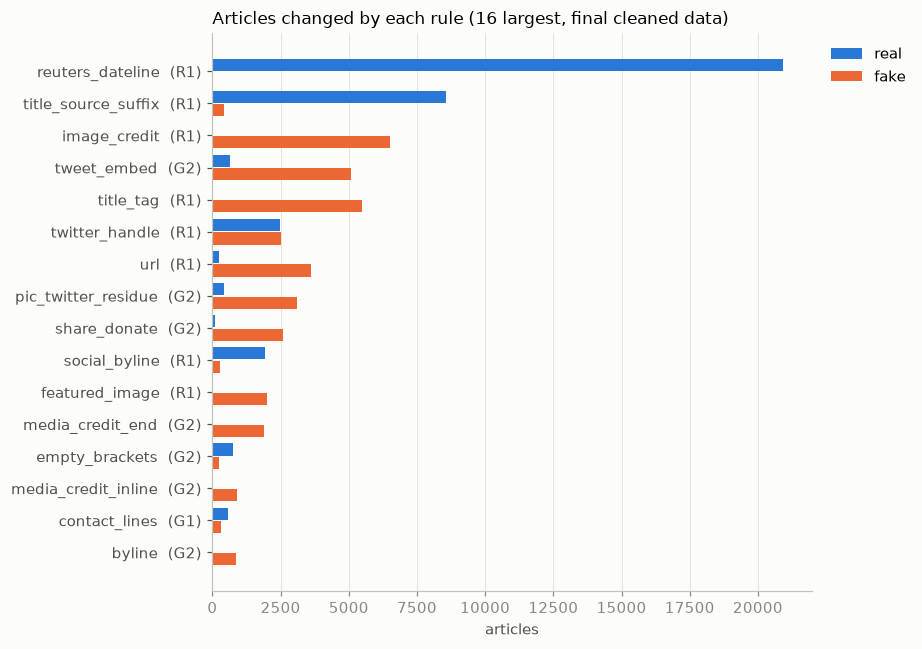

In [9]:
top = hits.assign(total=hits.kept_real + hits.kept_fake).nlargest(16, "total")
fig, ax = plt.subplots(figsize=(8.5, 6))
class_bars(ax, top.rule + "  (" + top.group + ")", top.kept_real, top.kept_fake,
           "Articles changed by each rule (16 largest, final cleaned data)")
save(fig, "cleaning_rules")
plt.show()

Almost every rule fires overwhelmingly in one class: exactly the kind of signal a classifier would otherwise
pick up instead of the content. A few, like `twitter_handle`, fire in both classes; removing them keeps the
treatment symmetric.

### Before and after

One real (Reuters) and one fake article, start and end of the text, raw (normalized) vs cleaned:

In [10]:
clean = load_clean(columns=["title", "text", "n_words"])
raw_by_id, clean_by_id = raw.set_index("doc_id"), clean.set_index("doc_id")


def before_after(doc_id, chars=320):
    r, c = raw_by_id.loc[doc_id], clean_by_id.loc[doc_id]
    print(f"doc_id {doc_id}  ({'fake' if c.is_fake else 'real'})")
    for name, t, x in (("BEFORE", normalize(str(r.title)), normalize(str(r.text))), ("AFTER", c.title, c.text)):
        print(f"\n--- {name} | title: {t}")
        print(textwrap.fill(x[:chars], 115) + "\n   [...]\n" + textwrap.fill(x[-chars:], 115))
    print("\n" + "=" * 115)


in_clean = raw.doc_id.isin(clean.doc_id)
before_after(raw[in_clean & text.str.contains(r"\(Reuters\)") & text.str.contains("is the sponsor")].doc_id.iloc[0])
before_after(raw[in_clean & text.str.contains(r"\(@\w+\) \w+ \d+, 20\d\d") & text.str.contains("Featured image via")].doc_id.iloc[0])

doc_id 626  (real)

--- BEFORE | title: Republican debate draws 13.5 million viewers for CBS: network
WASHINGTON (Reuters) - Saturday night's Republican debate on CBS was the most-watched of any in 2016, drawing 13.5
million viewers, the network said on Sunday. The CBS News debate was the most watched of the year so far and the
highest rated debate among adults aged 25-54 since January, the network said. In August, the
   [...]
ntial primary debate and the highest non-sports telecast in cable TV history, according to Nielsen. (Reporting by
Doina Chiacu; Editing by Jonathan Oatis) SAP is the sponsor of this content. It was independently created by
Reuters' editorial staff and funded in part by SAP, which otherwise has no role in this coverage.

--- AFTER | title: Republican debate draws 13.5 million viewers for CBS: network
Saturday night's Republican debate on CBS was the most-watched of any in 2016, drawing 13.5 million viewers, the
network said on Sunday. The CBS News debate was the 

doc_id 38  (fake)

--- BEFORE | title: Emboldened NRA Threatens New York Times: 'We're Coming For You' (VIDEO)
The NRA has a new favorite toy, but there are no bullets involved except maybe the bullet points they include in
their scripts. Dana Loesch has transformed herself from useful Fox News idiot to darling of the Second Amendment,
and the NRA is more than happy to put her stern but beautiful face on camera. Earlier this ye
   [...]
nfused about what s real and what s not and it s not the New York Times. Watch the video here:.@DLoesch has a
message for the @nytimes: We're coming for you. One non-#fakenews story is not enough. #NRA #ClenchedFistofTruth
pic.twitter.com/Hm1QkJi5Tp NRATV (@NRATV) August 3, 2017Featured image via Alex Wong/Getty Images

--- AFTER | title: Emboldened NRA Threatens New York Times: 'We're Coming For You'
The NRA has a new favorite toy, but there are no bullets involved except maybe the bullet points they include in
their scripts. Dana Loesch has transforme

## 5. Dropped rows

Rows are dropped in this order (a row gets the first reason that applies):

In [11]:
dropped = pd.read_csv(LOG / "dropped_rows.csv")
display(pd.DataFrame({"rule": ROW_FILTERS}).rename_axis("reason"))
dropped.groupby("reason").is_fake.agg(real=lambda s: int((s == 0).sum()), fake=lambda s: int((s == 1).sum()))

,rule
reason,
empty_text,Text is empty after normalization and marker removal (782 of the 783 originally empty texts are fake).
non_english,"Not English (G3): >30% of letters outside the Latin script (Cyrillic, Arabic, ...), or, for texts with >= 20 words, more Spani..."
duplicate,Exact duplicate of the cleaned content of an article with a lower doc_id (the lowest is kept).
conflicting_labels,The same cleaned content appears with both labels (all copies dropped).


,real,fake
reason,,
duplicate,270,7994
empty_text,1,882
non_english,1,461


- **Empty texts** are fake in 882 of 883 cases (after cleaning), so keeping them would let a model learn "no text → fake". The
  WELFake paper imputes missing values instead; for an article there is nothing meaningful to impute.
- **Duplicates** are detected on the *cleaned* title + text, which also catches copies that differed only in a
  marker. The lowest `doc_id` is kept. No cleaned content carries both labels.

### Language filter (G3)

In [12]:
ne = dropped[dropped.reason == "non_english"].merge(raw[["doc_id", "text"]], on="doc_id")
display(Markdown("**Examples**"))
display(ne.sample(8, random_state=1).assign(text=lambda d: d.text.str[:120])[["doc_id", "is_fake", "text"]])
display(Markdown("**The only real article dropped**"))
ne[ne.is_fake == 0].assign(text=lambda d: d.text.str[:200])[["doc_id", "text"]]

**Examples**

,doc_id,is_fake,text
330,52962,1,"Страна: Малайзия В своей новой статье постоянный обозреватель НВО Тони Карталучи отмечает, что Вашингтон продолжает попы"
101,14207,1,Desgranamos los perfiles de los posibles nuevos Ministros RAJOY REJUVENECE EL GOBIERNO PONIENDO DE MINISTRAS A LA YENNI
191,28869,1,"Rusia, China y Arabia Saudita ponen en jaque la hegemonía del dólar por Ariel Noyola Rodríguez Estados Unidos encuentra"
66,10457,1,فضيحة جنسية تهز أحد أشهر قارئي القرآن وتحرج سلطات إيران \nتاريخ النشر: 26.10.2016 | 15:35 GMT | أحد أشهر قارئي القرآن سعي
326,52402,1,Общество » Практика » Как заработать В советские времена стать писателем было довольно трудно. Недостаточно было просто
450,70662,1,Nula exhibición balompédica sobre campo desierto RESUMEN DE LA JORNADA 12 DE LA LIGA SANTANDER 2016-2017 Resumen de la j
225,37136,1,"Samstag, 19. November 2016 Bremen ersetzt als erstes Bundesland Schulnoten durch Emojis Bremen (Archiv) - Deutsch: 😳, Sp"
246,39327,1,"0 комментариев 0 поделились Действительный член РАН, директор Мурманского морского биологического института, председател"


**The only real article dropped**

,doc_id,text
426,67577,Les voix des femmes musulmanes ont été quasiment noyées par le débat agité sur l’interdiction de se baigner en burkini sur les...


Spanish, French, German, Russian, Arabic and others, nearly all labelled fake. Language alone would give these
away, and the English sentence-embedding model cannot read them. The single real one is French, so dropping it is
correct too. Texts under 20 words are never dropped by this filter.

## 6. What we keep on purpose (G4–G8)

Not everything that differs between the classes is a marker. Counts on the cleaned **training** split:

In [13]:
train_ids = load_splits().query("split_random == 'train'").doc_id
tr = clean[clean.doc_id.isin(train_ids)]
yt = tr.is_fake
display(class_table({
    'G4: "Mr./Ms./Mrs." honorific': per_class(tr.text.str.contains(r"\bM(?:r|s|rs)\. [A-Z]"), yt),
    'G4: "said on <weekday>"': per_class(tr.text.str.contains(r"said on (?:Mon|Tues|Wednes|Thurs|Fri|Satur|Sun)day"), yt),
    'G5: "Rohingya"': per_class(tr.text.str.contains("Rohingya"), yt),
    'G5: "Bundy"': per_class(tr.text.str.contains("Bundy"), yt),
    'G6: "told Reuters"': per_class(tr.text.str.contains("told Reuters"), yt),
    "G7: text under 20 words": per_class(tr.n_words < 20, yt),
}))
pd.DataFrame(KEPT_SIGNALS)[["group", "name", "reason"]]

,real,fake,share_fake
"G4: ""Mr./Ms./Mrs."" honorific",4388,1548,0.261
"G4: ""said on <weekday>""",5849,147,0.025
"G5: ""Rohingya""",268,2,0.007
"G5: ""Bundy""",7,149,0.955
"G6: ""told Reuters""",1911,49,0.025
G7: text under 20 words,18,268,0.937


,group,name,reason
0,G4,outlet house style,"Written by the author, not boilerplate. Documented as a limitation: part of the remaining signal is the house style of the out..."
1,G5,topic and time,This is the topic overlap the research question is about; the cluster-held-out split measures it. Removing it would hide the e...
2,G6,outlet names inside sentences,Part of the sentence the author wrote; bylines and promos outside the article body are removed (G1).
3,G7,very short texts,"Decided 2026-11-12: kept. They are the articles as published (teasers, stubs), not a source marker; dropping them would select..."
4,G8,title labels,Decided 2026-11-12: kept as part of the published headline. Documented (notebooks/02-data-cleaning) so their effect can be dis...


These are strong signals too, but they are **what the authors wrote**: house style, the topics each source
covered in its time window, the outlets they cite, the articles as published. Removing them would mean rewriting
the articles. They stay in the data and are part of the results: the cluster-held-out split measures how much
accuracy depends on topic, and the report names house style as a limitation.

### Title labels (G8)

Titles starting with "Something:" are either **editorial labels** (a site's section, series or kicker:
"BREAKING:", "Factbox:", "Review:") or **subjects** ("Trump:", "Kremlin:"). Training split, labels with ≥ 15
titles:

In [14]:
EDITORIAL = {"WATCH", "Watch", "BREAKING", "Breaking", "BREAKING NEWS", "JUST IN", "REPORT", "Report", "VIDEO",
             "BUSTED", "FLASHBACK", "BOMBSHELL", "UPDATE", "Chart Of The Day", "Life", "Re",
             "Factbox", "Exclusive", "Review", "Highlights", "California Today", "Breitbart News Daily"}
tr_raw = raw[raw.doc_id.isin(train_ids)]
prefix = tr_raw.title.fillna("").map(normalize).str.extract(r"^([A-Za-z][A-Za-z' ]{0,24}?)\s*:\s")[0]
tab = pd.DataFrame({"prefix": prefix, "label": tr_raw.label}).dropna().groupby("prefix")["label"].agg(titles="size", fake="sum")
tab["real"] = tab.titles - tab.fake
tab["share_fake"] = (tab.fake / tab.titles).round(3)
tab["kind"] = np.where(tab.index.isin(EDITORIAL), "editorial label", "subject")
tab = tab[tab.titles >= 15].sort_values("titles", ascending=False)[["kind", "titles", "real", "fake", "share_fake"]]
tab

,kind,titles,real,fake,share_fake
prefix,,,,,
WATCH,editorial label,702,17,685,0.976
BREAKING,editorial label,392,0,392,1.000
Factbox,editorial label,302,302,0,0.000
Exclusive,editorial label,140,137,3,0.021
Report,editorial label,96,78,18,0.188
Re,editorial label,86,0,86,1.000
Trump,subject,62,42,20,0.323
REPORT,editorial label,52,1,51,0.981
Review,editorial label,50,49,1,0.020


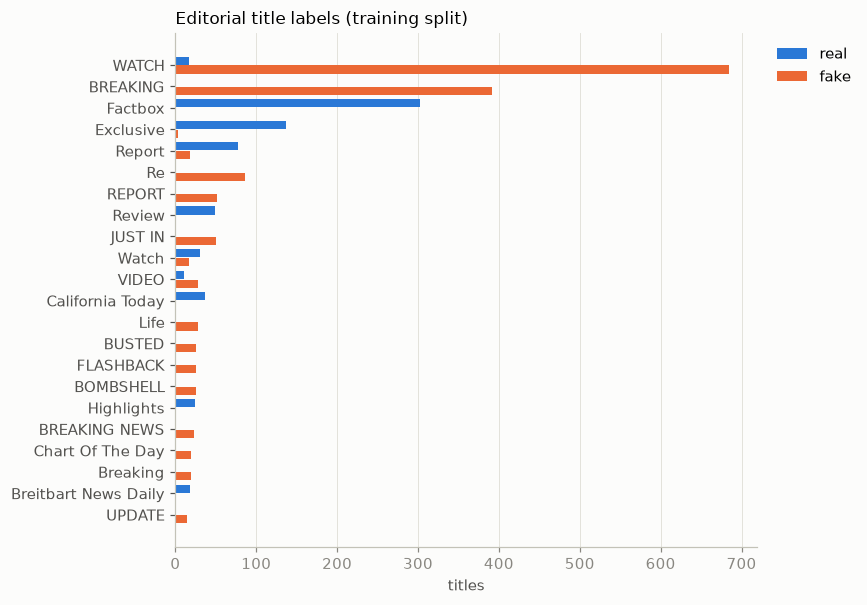

In [15]:
lab = tab[tab.kind == "editorial label"]
fig, ax = plt.subplots(figsize=(8, 5.6))
class_bars(ax, lab.index, lab.real, lab.fake, "Editorial title labels (training split)", xlabel="titles")
save(fig, "title_labels")
plt.show()

Editorial labels are almost perfectly one class ("BREAKING:", "JUST IN:", "Re:" ~100% fake; "Factbox:",
"Review:", "Highlights:" 0%), subjects are mixed. **Decision (2026-11-12): kept** as part of the published
headline. They are documented here so their effect can be discussed in the report. The shared `content` column is
lower-cased, so capitalization ("REPORT:" 96% fake vs "Report:" 21%) does not reach the models that use it.

### Very short texts (G7)

**Decision (2026-11-12): kept.** They are the articles as published (teasers, stubs), not a marker of the source;
dropping them would select rows on a property that correlates with the label.

In [16]:
short = clean.n_words < 20
display(class_table({"cleaned texts under 20 words": per_class(short, clean.is_fake)}))
clean[short].sample(6, random_state=0)[["doc_id", "is_fake", "title", "text"]]

,real,fake,share_fake
cleaned texts under 20 words,32,353,0.917


,doc_id,is_fake,title,text
42076,46396,1,World in fear of Trump following through. Hopefully no more soon.,Nice Admin Lady
51333,57686,1,"All Governments Lie, the Movie",All Governments Lie
24375,25977,1,,How about adding that he is a CHRISTIAN!!!
9427,9775,0,Cruz's immigration gambit,A verdict in 2017 could have sweeping consequences for tech startups.
33686,36539,1,,Part 9 Religious Fraud
47932,53491,1,,"""a no brainer"""


## 7. Result and the final dataset

,rows
raw_rows,72134
dropped_empty_text,883
dropped_non_english,462
dropped_conflicting_labels,0
dropped_duplicates,8264
clean_rows,62525


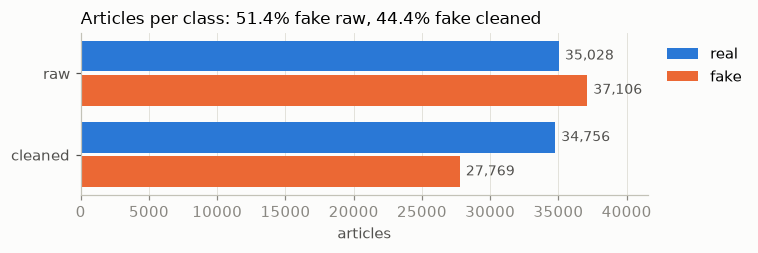

In [17]:
summary = json.loads((LOG / "cleaning_summary.json").read_text())
display(pd.Series(summary["rows"]).to_frame("rows"))
raw_counts, clean_counts = labels.value_counts().reindex([0, 1]), clean.is_fake.value_counts().reindex([0, 1])
fig, ax = plt.subplots(figsize=(7, 2.4))
class_bars(ax, ["raw", "cleaned"], [raw_counts[0], clean_counts[0]], [raw_counts[1], clean_counts[1]],
           f"Articles per class: {raw_counts[1] / raw_counts.sum():.1%} fake raw, "
           f"{clean_counts[1] / clean_counts.sum():.1%} fake cleaned", values=True)
save(fig, "cleaning_class_balance")
plt.show()

### Leak scan after round 2

The same scan on the final data and its shared training split:

In [18]:
after = leak_scan(load_dataset("random", columns=["content"]).query("split == 'train'"))
display(Markdown("**Leak scan before and after round 2** (training split; phrases in ≥ 50 articles that are ≥ 98% one class)"))
display(pd.DataFrame({name: {"one-class phrases": len(p), "fake-only": int((p.side == "FAKE").sum()),
                             "real-only": int((p.side == "REAL").sum())}
                      for name, p in (("before", before), ("after", after))}))
display(Markdown("**All fake-only phrases left after round 2**"))
after[after.side == "FAKE"][cols]

43,767 training articles: **307** of 64,906 frequent phrases are ≥ 98% one class (46 fake-only, 261 real-only).

**Leak scan before and after round 2** (training split; phrases in ≥ 50 articles that are ≥ 98% one class)

,before,after
one-class phrases,532,307
fake-only,218,46
real-only,314,261


**All fake-only phrases left after round 2**

,phrase,docs,real,fake,pos,example
0,video below,375,4,371,0.34,"…the nephilim at all, or even if you haven t, i m sure you ll find the video below refreshingly different than many other vide..."
11,october 27,184,2,182,0.11,"…t nasty! why does sally kohn hate women so much? posted at 4:56 pm on october 27, 2016 by sam j. so tired of the notion that ..."
43,world news,115,1,114,0.12,"…hat he deserved - and that s not even the real kicker. yesterday, mad world news reported on james otis, the man who was reco..."
44,interview below,114,0,114,0.99,"…correct, we can expect much gnashing of teeth on the right. watch the interview below:"
57,malheur,101,2,99,0.14,"…slims and one of the terrorists responsible for the occupation of the malheur national wildlife refuge in oregon, managed to ..."
62,henningsen,98,0,98,0.03,"…russian witch hunt is now collapsing before our eyes. as host patrick henningsen revealed last wednesday on acr radio, the su..."
63,patrick henningsen,98,0,98,0.06,…ngton s russian witch hunt is now collapsing before our eyes. as host patrick henningsen revealed last wednesday on acr radio...
68,zero hedge,97,1,96,0.19,"…alais ""jungle"" burns, refugees try to storm their way back in source: zero hedge it has been a harsh week for the 8,000 refug..."
72,the bundy,91,1,90,0.20,…began appearing at idiotic movements all over the place. his last was the bundy fiasco in oregon. ritzheimer has proven he wi...
77,hissy,87,0,87,0.22,"…ithin an hour of president obama s remarks, ben carson was throwing a hissy fit on fox news. now is definitely not the time t..."


Fake-only phrases fell from 218 to 46; what remains is topic, style and the title labels we keep.

### The final dataset

In [19]:
splits = load_splits()
final = clean.merge(splits, on="doc_id")
display(final.groupby("split_random").is_fake.agg(articles="size", share_fake="mean").reindex(["train", "val", "test"]).round(3))
final.groupby(final.is_fake.map({0: "real", 1: "fake"})).n_words.describe(percentiles=[0.05, 0.5, 0.95]).round(0)

,articles,share_fake
split_random,,
train,43767,0.444
val,9379,0.444
test,9379,0.444


,count,mean,std,min,5%,50%,95%,max
is_fake,,,,,,,,
fake,27769.0,523.0,662.0,1.0,44.0,391.0,1395.0,24565.0
real,34756.0,592.0,575.0,10.0,78.0,437.0,1453.0,14884.0


**62,525 articles, 44.4% fake**, split 70/15/15 with the same class balance in every part. This is what
`load_dataset("random")` returns. Every figure in this notebook is in `reports/figures/`.